# Figure 5c
Probability $p_1$ of a fixation location on island $1$ against the migration probabilities $m_{12}$ and $m_{21}$, for $N=20$ at $r=1$ and $r\to\infty$. The color scale maps $p_1\le1/2$ to $(2p_1)^{14}/2$ and $p_1>1/2$ to $1-(2(1-p_1))^{14}/2$, so only values close to $1/2$ are pale.

In [1]:
import json

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import FuncNorm, LinearSegmentedColormap

from fixloc import style as S

d = json.load(open('data.json'))
CM_P1 = LinearSegmentedColormap.from_list('p1', [S.PURPLE, (1, 1, 1), S.GREEN])
gam = 14.0


def fwd(x):
  x = np.asarray(x)
  return np.where(x <= 0.5, 0.5 * (2 * x) ** gam, 1 - 0.5 * (2 * (1 - x)) ** gam)


def inv(y):
  y = np.asarray(y)
  return np.where(y <= 0.5, 0.5 * (2 * y) ** (1 / gam), 1 - 0.5 * (2 * (1 - y)) ** (1 / gam))


NORM_P1 = FuncNorm((fwd, inv), vmin=0, vmax=1)

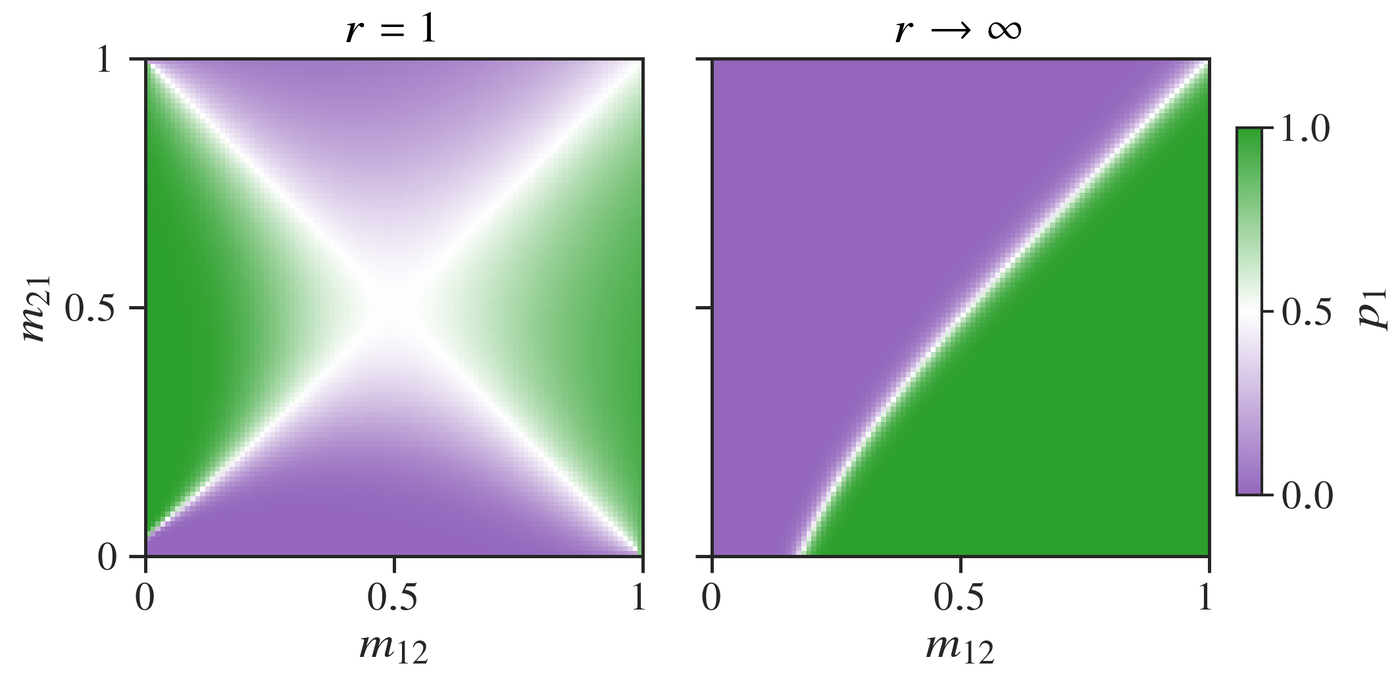

In [2]:
fig = plt.figure(figsize=(7.0, 6.2))
for k, (r, title) in enumerate((('1', r'$r=1$'), ('inf', r'$r\to\infty$'))):
  g = d[r]
  ax = fig.add_axes([0.075 + 0.205 * k, 0.385, 0.18, 0.18 * 7.0 / 6.2])
  extent = [min(g['m12']), max(g['m12']), min(g['m21']), max(g['m21'])]
  ax.imshow(np.array(g['p1']), origin='lower', extent=extent, cmap=CM_P1, norm=NORM_P1, aspect='auto', rasterized=True)
  ax.set_xlim(0, 1)
  ax.set_ylim(0, 1)
  ax.set_xticks([0, 0.5, 1])
  ax.set_xticklabels([r'$0$', r'$0.5$', r'$1$'])
  ax.set_yticks([0, 0.5, 1])
  ax.set_yticklabels([r'$0$', r'$0.5$', r'$1$'] if k == 0 else [])
  ax.set_xlabel(r'$m_{12}$', labelpad=1.5)
  if k == 0:
    ax.set_ylabel(r'$m_{21}$', labelpad=2.5)
  ax.set_title(title, fontsize=8, pad=3)
  for side in ('top', 'right'):
    ax.spines[side].set_visible(True)
cax = fig.add_axes([0.47, 0.41, 0.009, 0.15])
cb = fig.colorbar(plt.cm.ScalarMappable(cmap=CM_P1, norm=NORM_P1), cax=cax)
cb.outline.set_linewidth(0.5)
cb.set_ticks([0, 0.5, 1])
cb.ax.tick_params(length=2.2, width=0.5, pad=1.5)
cb.set_label(r'$p_1$', labelpad=2.5)
S.save_panel(fig, 'c')